In [2]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

print("Dataset Shape:", df.shape)
display(df.head())

print("\nContent Type Distribution:")
print(df['type'].value_counts())

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Content Type Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


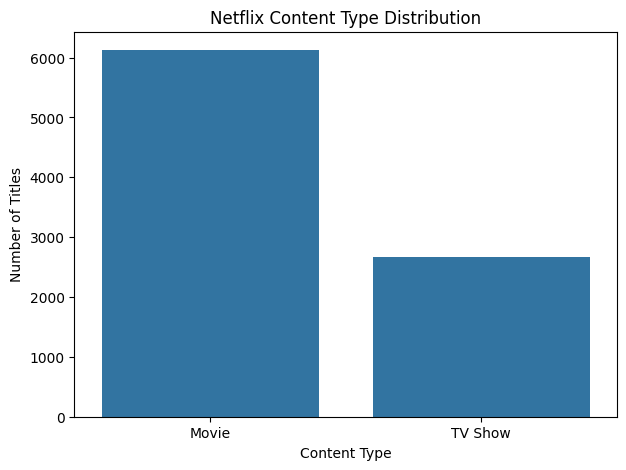

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='type')

plt.title('Netflix Content Type Distribution')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.savefig('content_type_distribution.png', dpi=300)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Select features
features = ['release_year', 'rating', 'country', 'listed_in', 'duration']

X = df[features].copy()

# Define target variable
y = df['type'].copy()

# Handle missing values
X = X.fillna('Unknown')

# Encode target variable
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Display results
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Target Classes:", label_encoder.classes_)

display(X.head())

Features Shape: (8790, 5)
Target Shape: (8790,)
Target Classes: ['Movie' 'TV Show']


,release_year,rating,country,listed_in,duration
0,2020,PG-13,United States,Documentaries,90 min
1,2021,TV-MA,France,"Crime TV Shows, International TV Shows, TV Act...",1 Season
2,2021,TV-MA,United States,"TV Dramas, TV Horror, TV Mysteries",1 Season
3,2021,TV-PG,Brazil,"Children & Family Movies, Comedies",91 min
4,1993,TV-MA,United States,"Dramas, Independent Movies, International Movies",125 min


In [6]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7032, 5)
Testing Data: (1758, 5)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns
numeric_features = ['release_year']
categorical_features = ['rating', 'country', 'listed_in', 'duration']

# Preprocessing
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# Random Forest Model
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [8]:
from sklearn.metrics import accuracy_score, classification_report

# Predictions
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

Model Accuracy: 99.72 %

Classification Report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      0.99      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



In [9]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression Pipeline
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train model
lr_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [10]:
from sklearn.metrics import accuracy_score
import pandas as pd

# Predictions
rf_predictions = rf_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

# Calculate accuracy
results = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, lr_predictions)
    ]
})

results['Accuracy (%)'] = (results['Accuracy'] * 100).round(2)

display(results)

,Model,Accuracy,Accuracy (%)
0,Random Forest,0.997156,99.72
1,Logistic Regression,0.998862,99.89


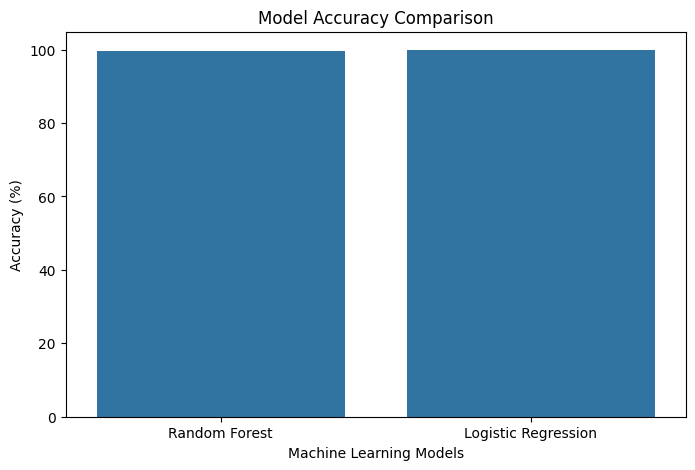

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy (%)'
)

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.xlabel('Machine Learning Models')

plt.savefig('model_comparison.png', dpi=300)
plt.show()

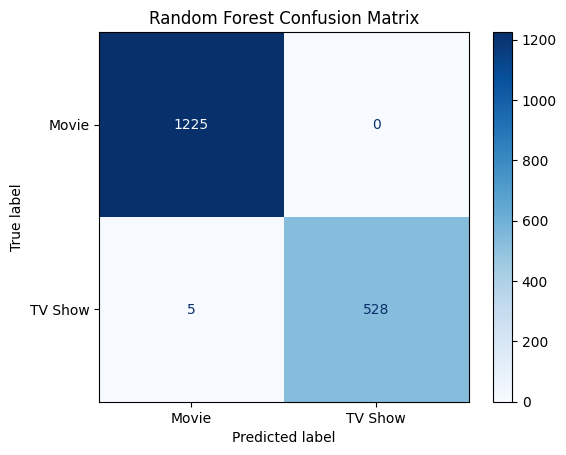

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, rf_predictions)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Random Forest Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

In [13]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    rf_predictions,
    target_names=label_encoder.classes_
))

Random Forest Classification Report:

              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      0.99      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



In [14]:
best_model = (
    rf_model
    if accuracy_score(y_test, rf_predictions) >= accuracy_score(y_test, lr_predictions)
    else lr_model
)

print("Best Model:",
      "Random Forest" if best_model == rf_model
      else "Logistic Regression")

Best Model: Logistic Regression


In [15]:
# Test model with new content
new_content = pd.DataFrame({
    'release_year': [2022],
    'rating': ['TV-MA'],
    'country': ['United States'],
    'listed_in': ['Dramas, International Movies'],
    'duration': ['90 min']
})

prediction = best_model.predict(new_content)

predicted_type = label_encoder.inverse_transform(prediction)

print("Predicted Content Type:", predicted_type[0])

Predicted Content Type: Movie


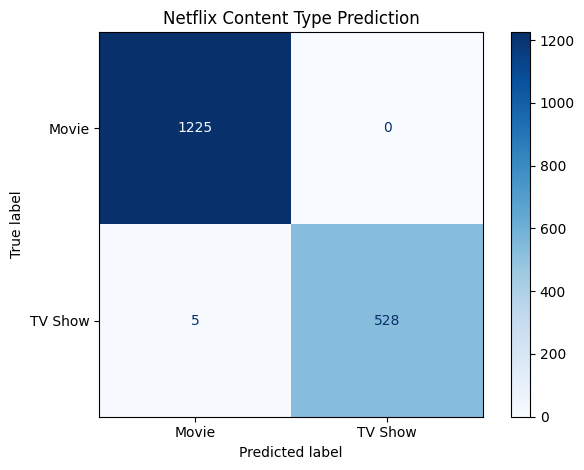

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=label_encoder.classes_,
    cmap='Blues',
    values_format='d'
)

plt.title("Netflix Content Type Prediction")
plt.tight_layout()
plt.savefig("content_type_confusion_matrix.png", dpi=300)
plt.show()

# Task 2: Netflix Content Type Prediction Model

## 1. Project Overview

This project uses Machine Learning to predict whether a Netflix title belongs to the Movie or TV Show category based on its available features.

## 2. Dataset

* Dataset: Netflix Titles Dataset
* Total Records: 8,790
* Total Features: 10
* Target Variable: Type
* Classes: Movie and TV Show

## 3. Technologies Used

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-learn
* Google Colab

## 4. Data Preprocessing

* Loaded and inspected the dataset.
* Selected relevant features.
* Handled missing values.
* Encoded the target variable.
* Split the dataset into training and testing sets.

## 5. Machine Learning Models

Two classification algorithms were implemented:

* Random Forest Classifier
* Logistic Regression

## 6. Model Evaluation

The models were evaluated using:

* Accuracy
* Precision
* Recall
* F1-score
* Confusion Matrix

## 7. Prediction Testing

The trained model was tested on a new Netflix content sample and predicted its content type as Movie.

## 8. Conclusion

The project demonstrates how machine learning classification algorithms can be used to predict Netflix content categories. The model comparison and evaluation metrics help assess classification performance.
